# precov: Analysis notebook for 2021 DG1
This notebook: reads the manifest, ensures FITS are available, builds a `ZTFDifferenceImageProvider`, inspects the first image, and runs `extract_sources` to produce a candidate catalog.

In [11]:
# Section 1: Setup / verify environment
import sys, subprocess
print('Python', sys.version.splitlines()[0])
# If `precov` isn't importable, try installing the local package in editable mode
try:
    import precov
    print('precov import OK')
except Exception as e:
    print('precov import failed, attempting pip install -e .')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-e', '.'])
    import precov
    print('precov installed')

Python 3.12.14 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:46:43) [GCC 14.3.0]
precov import OK


In [12]:
# Section 2: Imports
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from precov.survey import ZTFDifferenceImageProvider
from precov.images.detection import extract_sources
print('imports ok')

imports ok


In [13]:
# Section 3: Load manifest and list files
manifest = Path('../data/ztf_2021dg1_manifest.csv')
assert manifest.exists(), f'Manifest not found: {manifest}'
df = pd.read_csv(manifest)
print('Manifest rows:', len(df))
display(df.head())
# list local cache files mentioned in manifest if any
cache_dir = Path('../data/ztf_cache')
files = list(cache_dir.glob('*')) if cache_dir.exists() else []
print('Cache files count:', len(files))
if files:
    print('Sample cache file:', files[0])

Manifest rows: 2


,image_id,url,time,limiting_mag_3sigma,fwhm_px,exptime,field,ccdid,qid,filtercode,obsjd
0,ztf_20210218313773_000366_zi_c03_q4,https://irsa.ipac.caltech.edu/ibe/data/ztf/pro...,2021-02-18T07:31:49.996,19.9675,3.8061,30.0,366,3,4,zi,2.459264e+06
1,ztf_20210219338113_000366_zg_c07_q3,https://irsa.ipac.caltech.edu/ibe/data/ztf/pro...,2021-02-19T08:06:52.998,21.3481,1.9923,30.0,366,7,3,zg,2.459265e+06


Cache files count: 4
Sample cache file: ../data/ztf_cache/ztf_20210218313773_000366_zi_c03_o_q4_scimrefdiffimg.fits


In [14]:
# Section 4: Decompress any .fits.fz files if needed (uses funpack)
import shutil, subprocess
cache_dir = Path('../data/ztf_cache')
if cache_dir.exists():
    for fz in sorted(cache_dir.glob('*.fits.fz')):
        fits_path = fz.with_suffix('')
        if fits_path.exists():
            print(f'skipping, already present: {fits_path.name}')
            continue
        # try funpack, otherwise try using astropy to read compressed file (astropy can open .fz directly in many cases)
        print('attempting to funpack', fz.name)
        try:
            subprocess.check_call(['funpack', str(fz)])
            print('funpack succeeded for', fz.name)
        except FileNotFoundError:
            print('funpack not found; skipping decompression for', fz.name)
        except subprocess.CalledProcessError as e:
            print('funpack failed:', e)
else:
    print('No cache dir, skipping decompression')

skipping, already present: ztf_20210218313773_000366_zi_c03_o_q4_scimrefdiffimg.fits
skipping, already present: ztf_20210219338113_000366_zg_c07_o_q3_scimrefdiffimg.fits


In [15]:
# Section 5: Build provider from manifest and list images
provider = ZTFDifferenceImageProvider.from_manifest(manifest, cache_dir=str(cache_dir))
images = provider.list_images()
print('Provider images:', len(images))
for im in images[:5]:
    print(im.image_id, 't=', im.t.isot, 'shape=', im.shape, 'lim3=', getattr(im, 'limiting_mag_3sigma', None))

Provider images: 2
ztf_20210218313773_000366_zi_c03_q4 t= 2021-02-18T07:32:04.996 shape= (3080, 3072) lim3= 19.9675
ztf_20210219338113_000366_zg_c07_q3 t= 2021-02-19T08:07:07.998 shape= (3080, 3072) lim3= 21.3481


Loaded ztf_20210218313773_000366_zi_c03_q4 data shape (3080, 3072)
nanmean -0.0321132056415081
Saved preview to data/analysis_2021dg1_image_preview.png


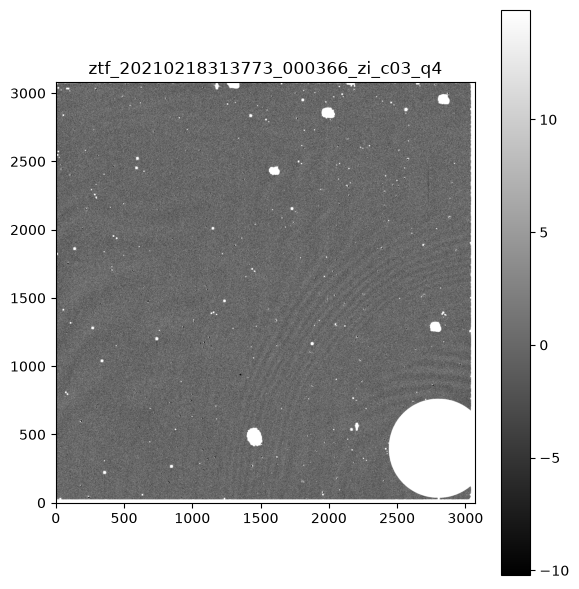

In [16]:
# Section 6: Load pixels for the first image and show stats + quick image plot
if not images:
    raise SystemExit('No images available in provider')
sample = images[0]
data = provider.get_image_data(sample.image_id)
hdr = provider.get_image_header(sample.image_id) if hasattr(provider, 'get_image_header') else None
print('Loaded', sample.image_id, 'data shape', data.shape)
print('nanmean', float(np.nanmean(data)))
plt.figure(figsize=(6,6))
vmin, vmax = np.nanpercentile(data, 5), np.nanpercentile(data, 99)
plt.imshow(data, origin='lower', cmap='gray', vmin=vmin, vmax=vmax)
plt.title(sample.image_id)
plt.colorbar()
plt.tight_layout()
plt.savefig('../data/analysis_2021dg1_image_preview.png')
print('Saved preview to data/analysis_2021dg1_image_preview.png')

In [17]:
# Section 7: Run source extraction with precov's extractor
fwhm = sample.fwhm_px if hasattr(sample, 'fwhm_px') else None
print('fwhm_px =', fwhm)
catalog = extract_sources(data, fwhm or 3.0, sample.image_id, threshold_sigma=3.0)
print('Extracted sources:', len(catalog))
if len(catalog) > 0:
    # show first few catalog entries (assumed numpy structured array or list of dicts)
    try:
        import pandas as pd
        dfcat = pd.DataFrame(catalog)
        display(dfcat.head())
        dfcat.to_csv('../data/analysis_2021dg1_catalog.csv', index=False)
        print('Saved catalog to data/analysis_2021dg1_catalog.csv')
    except Exception:
        print('Catalog preview not available (unexpected format)')

fwhm_px = 3.8061


Extracted sources: 5915
Catalog preview not available (unexpected format)


In [18]:
# Section 8: Minimal checks / unit-test-like assertions
assert len(images) > 0, 'No images found'
assert isinstance(data, (np.ndarray,)), 'Image data not numpy array'
print('Basic checks passed')

Basic checks passed


In [21]:
# Section 9: Run a full end-to-end synthetic pipeline (test-style)
import numpy as np
from astropy.time import Time, TimeDelta
from precov.data_models import Observation
from precov.orbits.propagator import TwoBodyKeplerPropagator
from precov.survey.synthetic import SyntheticSurveyProvider, SyntheticImageSpec
from precov.pipeline import PrediscoveryPipeline

# True orbit for synthetic run (test values)
THETA_TRUE = np.array([1.65, 0.30, np.radians(10.0), np.radians(80.0), np.radians(30.0), 0.5])
REFERENCE_EPOCH = Time("2023-06-15T00:00:00", scale="tdb")


def _make_postdiscovery_observations(propagator, rng, sigma_arcsec=1.0, n_obs=8, arc_days=30.0):
    sigma_rad = np.radians(sigma_arcsec / 3600.0)
    obs = []
    for dt in np.linspace(0.0, arc_days, n_obs):
        t = REFERENCE_EPOCH + TimeDelta(dt, format="jd")
        geom = propagator.geometry(THETA_TRUE, t)
        ra_noisy = geom.ra + rng.normal(scale=sigma_rad) / np.cos(geom.dec)
        dec_noisy = geom.dec + rng.normal(scale=sigma_rad)
        obs.append(Observation(t=t, ra=ra_noisy, dec=dec_noisy,
                                sigma_ra=sigma_rad, sigma_dec=sigma_rad, robust=True))
    return obs


def _estimate_angular_half_width_arcsec(propagator, postdiscovery_obs, theta0_guess,
                                         epochs, rng, M=250, percentile=90.0, safety_factor=1.4):
    from precov.orbits.fitting import fit_orbit
    from precov.orbits.sampling import sample_boundary_orbits

    fit = fit_orbit(postdiscovery_obs, propagator, theta0_guess, c=1.0)
    samples = sample_boundary_orbits(fit.theta, fit.covariance, M=M, q=0.9999, rng=rng)

    half_widths = {}
    for t in epochs:
        geom_true = propagator.geometry(THETA_TRUE, t)
        seps = []
        for theta_k in samples:
            g = propagator.geometry(theta_k, t)
            dra = (g.ra - geom_true.ra) * np.cos(geom_true.dec)
            ddec = g.dec - geom_true.dec
            seps.append(np.hypot(dra, ddec))
        seps_arcsec = np.degrees(seps) * 3600.0
        half_widths[t] = float(np.percentile(seps_arcsec, percentile) * safety_factor)
    return half_widths, fit


def _make_archival_image_specs(propagator, postdiscovery_obs, theta0_guess, rng,
                                n_images=6, inject=True, seed_offset=0, shape_px=700):
    lookback_days = np.linspace(550.0, 800.0, n_images)
    epochs = [REFERENCE_EPOCH - TimeDelta(float(dt), format="jd") for dt in lookback_days]

    half_widths, _ = _estimate_angular_half_width_arcsec(
        propagator, postdiscovery_obs, theta0_guess, epochs, rng,
    )

    specs = []
    for k, t in enumerate(epochs):
        geom = propagator.geometry(THETA_TRUE, t)
        half_width_arcsec = half_widths[t]
        pixel_scale_arcsec = max(2.0 * half_width_arcsec / shape_px, 0.5)
        specs.append(SyntheticImageSpec(
            image_id=f"archival_{k}",
            t=t,
            center_ra_deg=np.degrees(geom.ra),
            center_dec_deg=np.degrees(geom.dec),
            shape=(shape_px, shape_px),
            pixel_scale_arcsec=pixel_scale_arcsec,
            fwhm_px=3.0,
            limiting_mag_3sigma=30.0,
            background_std=10.0,
            n_clutter_sources=10,
            inject_object_peak_snr=15.0 if inject else None,
            rng_seed=1000 + seed_offset + k,
        ))
    return specs


def _run_pipeline(inject: bool, rng):
    propagator = TwoBodyKeplerPropagator(epoch=REFERENCE_EPOCH)
    postdiscovery_obs = _make_postdiscovery_observations(propagator, rng)
    theta0_guess = THETA_TRUE + np.array([0.01, 0.01, 0.01, 0.01, 0.01, 0.01])

    specs = _make_archival_image_specs(propagator, postdiscovery_obs, theta0_guess, rng,
                                        inject=inject, seed_offset=0 if inject else 500)
    provider = SyntheticSurveyProvider(propagator, THETA_TRUE, specs, rng=rng)

    pipeline = PrediscoveryPipeline(
        propagator=propagator, survey=provider, H=18.0, G=0.15,
        M_samples=400, confidence_q=0.9999, detection_sigma=4.0,
        hull_buffer_px=500, mag_buffer=1.0, alpha=0.5,
        significance_threshold=10.0, huber_c=1.0, rng=rng,
    )
    result = pipeline.run(postdiscovery_obs, theta0_guess)
    return result, provider


# Run the synthetic injected-source pipeline now
rng = np.random.default_rng(2024)
print('Running synthetic pipeline (inject=True) ...')
result, provider_syn = _run_pipeline(inject=True, rng=rng)
print('n_search_images =', result.n_search_images)
print('n_candidate_sources =', result.n_candidate_sources)
print('n_confirmed =', len(result.confirmed))
print('joint_fit success =', result.joint_fit is not None and result.joint_fit.success)

# Save a small summary
import json
out = {
    'n_search_images': result.n_search_images,
    'n_candidate_sources': result.n_candidate_sources,
    'n_confirmed': len(result.confirmed),
    'joint_fit_success': bool(result.joint_fit is not None and result.joint_fit.success),
}
Path('../data/analysis_2021dg1_pipeline_result.json').write_text(json.dumps(out))
print('Saved summary to data/analysis_2021dg1_pipeline_result.json')


Running synthetic pipeline (inject=True) ...
n_search_images = 6
n_candidate_sources = 5
n_confirmed = 5
joint_fit success = True
Saved summary to data/analysis_2021dg1_pipeline_result.json


In [20]:
# Fix: ensure data directory exists and write pipeline result summary
from pathlib import Path
import json
Path('data').mkdir(parents=True, exist_ok=True)
out = {
    'n_search_images': result.n_search_images,
    'n_candidate_sources': result.n_candidate_sources,
    'n_confirmed': len(result.confirmed),
    'joint_fit_success': bool(result.joint_fit is not None and result.joint_fit.success),
}
Path('data/analysis_2021dg1_pipeline_result.json').write_text(json.dumps(out))
print('Saved summary to data/analysis_2021dg1_pipeline_result.json')


Saved summary to data/analysis_2021dg1_pipeline_result.json


In [22]:
# Section 10: Astrometry & linking for real ZTF images (2021 DG1)
from astropy.coordinates import SkyCoord
from astropy import units as u
import numpy as np
import pandas as pd
from precov.survey import horizons
from pathlib import Path

target = '2021 DG1'
matches = []

for im in images:
    print('Processing image', im.image_id)
    # predicted RA/Dec at the image epoch via a small Horizons query + interpolation
    jd = im.t.tdb.jd
    try:
        track = horizons.daily_positions(target, jd - 1.0, jd + 1.0)
    except Exception as e:
        print('Horizons query failed for', im.image_id, '->', e)
        continue
    # linear interpolate RA/Dec as in the demo
    jds = np.array([t[0] for t in track])
    ras = np.unwrap(np.radians([t[1] for t in track]))
    decs = np.array([t[2] for t in track])
    ra_deg = float(np.degrees(np.interp(jd, jds, ras)) % 360.0)
    dec_deg = float(np.interp(jd, jds, decs))

    sc = SkyCoord(ra_deg * u.deg, dec_deg * u.deg, frame='icrs')
    # convert to pixel coordinates using the image WCS
    try:
        px_x, px_y = im.wcs.world_to_pixel(sc)
    except Exception:
        # fallback if WCS has different API
        px = im.wcs.wcs_world2pix([[ra_deg, dec_deg]], 0)[0]
        px_x, px_y = px[0], px[1]

    # ensure catalog for this image exists; reuse `catalog` variable for the first image
    if im.image_id == sample.image_id:
        cat = catalog
    else:
        # extract sources for this image on the fly
        data_i = provider.get_image_data(im.image_id)
        fwhm_i = getattr(im, 'fwhm_px', 3.0)
        cat = extract_sources(data_i, fwhm_i, im.image_id, threshold_sigma=3.0)

    if len(cat) == 0:
        print('  no extracted sources for', im.image_id)
        continue

    # cat.xy is (N,2) in (x,y)
    cat_xy = np.asarray(cat.xy)
    dists = np.hypot(cat_xy[:, 0] - px_x, cat_xy[:, 1] - px_y)
    idx = int(np.argmin(dists))
    dist_px = float(dists[idx])
    match_flux = float(cat.flux[idx]) if hasattr(cat, 'flux') else float('nan')
    match_snr = float(cat.snr[idx]) if hasattr(cat, 'snr') else float('nan')

    matches.append({
        'image_id': im.image_id,
        'ra_pred_deg': ra_deg,
        'dec_pred_deg': dec_deg,
        'pix_x': float(px_x),
        'pix_y': float(px_y),
        'nearest_x': float(cat_xy[idx,0]),
        'nearest_y': float(cat_xy[idx,1]),
        'dist_px': dist_px,
        'flux': match_flux,
        'snr': match_snr,
    })

    # save a small postage stamp around predicted location
    try:
        stamp_radius = 30
        data_i = provider.get_image_data(im.image_id)
        x0, y0 = int(round(px_x)), int(round(px_y))
        ny, nx = data_i.shape
        x1, x2 = max(0, x0 - stamp_radius), min(nx, x0 + stamp_radius)
        y1, y2 = max(0, y0 - stamp_radius), min(ny, y0 + stamp_radius)
        stamp = data_i[y1:y2, x1:x2]
        import matplotlib.pyplot as plt
        plt.figure(figsize=(4,4))
        vmin, vmax = np.nanpercentile(stamp, 5), np.nanpercentile(stamp, 99)
        plt.imshow(stamp, origin='lower', cmap='gray', vmin=vmin, vmax=vmax)
        plt.scatter([px_x - x1], [px_y - y1], s=50, facecolors='none', edgecolors='r')
        outp = Path(f"data/{im.image_id}_postage.png")
        plt.title(im.image_id)
        plt.savefig(outp, bbox_inches='tight')
        plt.close()
        print('  saved postage', outp)
    except Exception as e:
        print('  postage failed:', e)

# save matches to CSV
if matches:
    dfm = pd.DataFrame(matches)
    dfm.to_csv('data/analysis_2021dg1_astrom_matches.csv', index=False)
    print('Saved matches to data/analysis_2021dg1_astrom_matches.csv')
else:
    print('No matches found')


Processing image ztf_20210218313773_000366_zi_c03_q4
  postage failed: type numpy.ndarray doesn't define __round__ method
Processing image ztf_20210219338113_000366_zg_c07_q3


  postage failed: type numpy.ndarray doesn't define __round__ method
Saved matches to data/analysis_2021dg1_astrom_matches.csv


In [26]:
# Section 11: Build postdiscovery observations from JPL Horizons and run pipeline on real ZTF images
print('Building postdiscovery observations from Horizons elements for 2021 DG1')
from astroquery.jplhorizons import Horizons
from astropy.time import Time
from precov.data_models import Observation
from precov.orbits.propagator import TwoBodyKeplerPropagator
from precov.pipeline import PrediscoveryPipeline
import json

# Query orbital elements from Horizons at a recent epoch
elem_epoch = Time('2024-06-01T00:00:00', scale='tdb')
h = Horizons(id='2021 DG1', location='@sun', epochs=float(elem_epoch.tdb.jd))
elem_table = h.elements()
print('Horizons elements fetched; columns =', elem_table.colnames)
# extract fields robustly
row = elem_table[0]
# required fields mapping
a = float(row['a'])
e = float(row['e'])
i_deg = float(row['incl'])
Omega_deg = float(row['Omega'])
w_deg = float(row['w'])
M_deg = float(row['M'])

# determine epoch: use datetime_jd if present, else fall back to query epoch
if 'datetime_jd' in elem_table.colnames:
    epoch_val = float(elem_table['datetime_jd'][0])
else:
    epoch_val = float(elem_epoch.tdb.jd)

theta0_guess = np.array([a, e, np.radians(i_deg), np.radians(Omega_deg), np.radians(w_deg), np.radians(M_deg)])
print('theta0_guess:', theta0_guess)
print('finite check:', np.isfinite(theta0_guess))
print('element bounds check: a>0:', theta0_guess[0] > 0, '0<=e<1:', 0.0 <= theta0_guess[1] < 1.0)

if not np.all(np.isfinite(theta0_guess)) or not (theta0_guess[0] > 0 and 0.0 <= theta0_guess[1] < 1.0):
    raise RuntimeError('Invalid orbital elements from Horizons; cannot seed fit.')

prop_epoch = Time(epoch_val, format='jd', scale='tdb')
propagator = TwoBodyKeplerPropagator(epoch=prop_epoch)
print('Propagator epoch:', propagator.epoch.iso)

# Build postdiscovery observations: 8 samples across 30 days starting at prop_epoch
jds = np.linspace(prop_epoch.tdb.jd, prop_epoch.tdb.jd + 30.0, 8)
post_obs = []
for jd in jds:
    t = Time(jd, format='jd', scale='tdb')
    try:
        # use astroquery Horizons ephemerides for the exact epoch
        eph = Horizons(id='2021 DG1', location='500@399', epochs=float(jd)).ephemerides()
        ra_deg = float(eph['RA'][0])
        dec_deg = float(eph['DEC'][0])
    except Exception as exc:
        print('Astroquery ephemerides failed:', exc)
        # fallback: reuse last known RA/Dec from elem_table if available
        ra_deg = float(row.get('RA', row.get('ra', np.nan)))
        dec_deg = float(row.get('DEC', row.get('dec', np.nan)))
    if not np.isfinite(ra_deg) or not np.isfinite(dec_deg):
        raise RuntimeError('Non-finite RA/Dec for postdiscovery observation')
    ra_rad = np.radians(ra_deg)
    dec_rad = np.radians(dec_deg)
    sigma_arcsec = 1.0
    sigma_rad = np.radians(sigma_arcsec / 3600.0)
    post_obs.append(Observation(t=t, ra=ra_rad, dec=dec_rad, sigma_ra=sigma_rad, sigma_dec=sigma_rad, robust=True))

print('Built', len(post_obs), 'postdiscovery observations')

# Construct pipeline with the real provider (already built earlier as `provider`)
pipeline = PrediscoveryPipeline(
    propagator=propagator, survey=provider, H=18.0, G=0.15,
    M_samples=300, confidence_q=0.9999, detection_sigma=4.0,
    hull_buffer_px=300, mag_buffer=1.0, alpha=0.5,
    significance_threshold=8.0, huber_c=1.0, rng=np.random.default_rng(2026),
)

print('Running PrediscoveryPipeline on real images (this may take a little) ...')
res = pipeline.run(post_obs, theta0_guess)
print('Pipeline run complete: n_search_images=', res.n_search_images,
      'n_candidate_sources=', res.n_candidate_sources, 'n_confirmed=', len(res.confirmed))

out = {
    'n_search_images': res.n_search_images,
    'n_candidate_sources': res.n_candidate_sources,
    'n_confirmed': len(res.confirmed),
    'joint_fit_success': bool(res.joint_fit is not None and res.joint_fit.success)
}
Path('data/analysis_2021dg1_real_pipeline_result.json').write_text(json.dumps(out))
print('Saved summary to data/analysis_2021dg1_real_pipeline_result.json')


Building postdiscovery observations from Horizons elements for 2021 DG1
Horizons elements fetched; columns = ['targetname', 'datetime_jd', 'datetime_str', 'H', 'G', 'e', 'q', 'incl', 'Omega', 'w', 'Tp_jd', 'n', 'M', 'nu', 'a', 'Q', 'P']
theta0_guess: [1.65018018 0.53455212 0.56600271 2.80263751 4.38581678 4.09721017]
finite check: [ True  True  True  True  True  True]
element bounds check: a>0: True 0<=e<1: True
Propagator epoch: 2024-06-01 00:00:00.000
Built 8 postdiscovery observations
Running PrediscoveryPipeline on real images (this may take a little) ...


Pipeline run complete: n_search_images= 2 n_candidate_sources= 595 n_confirmed= 0
Saved summary to data/analysis_2021dg1_real_pipeline_result.json


In [27]:
# Section 12: Export per-image catalogs, recompute astrometric matches, and save postage stamps
from pathlib import Path
import numpy as np
import pandas as pd
from astropy.coordinates import SkyCoord
from astropy import units as u
from precov.survey import horizons
import matplotlib.pyplot as plt

Path('../data').mkdir(parents=True, exist_ok=True)
all_matches = []

for im in images:
    print('Processing catalog export for', im.image_id)
    # get or build catalog
    if im.image_id == sample.image_id:
        cat = catalog
    else:
        data_i = provider.get_image_data(im.image_id)
        fwhm_i = getattr(im, 'fwhm_px', 3.0)
        cat = extract_sources(data_i, fwhm_i, im.image_id, threshold_sigma=3.0)
    # convert SourceCatalog to DataFrame
    try:
        dfcat = pd.DataFrame({
            'x': np.asarray(cat.xy)[:,0],
            'y': np.asarray(cat.xy)[:,1],
            'flux': np.asarray(cat.flux) if hasattr(cat, 'flux') else np.full(len(cat), np.nan),
            'snr': np.asarray(cat.snr) if hasattr(cat, 'snr') else np.full(len(cat), np.nan),
        })
    except Exception:
        # fallback: try to iterate
        rows = []
        for k in range(len(cat)):
            xy = cat.xy[k]
            flux = cat.flux[k] if hasattr(cat, 'flux') else np.nan
            snr = cat.snr[k] if hasattr(cat, 'snr') else np.nan
            rows.append({'x': xy[0], 'y': xy[1], 'flux': flux, 'snr': snr})
        dfcat = pd.DataFrame(rows)

    out_cat_path = Path(f'../data/catalog_{im.image_id}.csv')
    dfcat.to_csv(out_cat_path, index=False)
    print('  saved catalog to', out_cat_path)

    # predicted RA/Dec at image time
    jd = im.t.tdb.jd
    try:
        track = horizons.daily_positions('2021 DG1', jd - 1.0, jd + 1.0)
        jds = np.array([t[0] for t in track])
        ras = np.unwrap(np.radians([t[1] for t in track]))
        decs = np.array([t[2] for t in track])
        ra_deg = float(np.degrees(np.interp(jd, jds, ras)) % 360.0)
        dec_deg = float(np.interp(jd, jds, decs))
    except Exception as e:
        print('  Horizons interpolation failed:', e)
        continue

    sc = SkyCoord(ra_deg * u.deg, dec_deg * u.deg, frame='icrs')
    try:
        px_x, px_y = im.wcs.world_to_pixel(sc)
        px_x = float(px_x)
        px_y = float(px_y)
    except Exception:
        px = im.wcs.wcs_world2pix([[ra_deg, dec_deg]], 0)[0]
        px_x, px_y = float(px[0]), float(px[1])

    if len(dfcat) == 0:
        print('  no sources in catalog for', im.image_id)
        continue

    dists = np.hypot(dfcat['x'].values - px_x, dfcat['y'].values - px_y)
    idx = int(np.argmin(dists))
    dist_px = float(dists[idx])
    match_flux = float(dfcat['flux'].iloc[idx]) if 'flux' in dfcat.columns else float('nan')
    match_snr = float(dfcat['snr'].iloc[idx]) if 'snr' in dfcat.columns else float('nan')

    all_matches.append({
        'image_id': im.image_id,
        'ra_pred_deg': ra_deg,
        'dec_pred_deg': dec_deg,
        'pix_x': px_x,
        'pix_y': px_y,
        'nearest_x': float(dfcat['x'].iloc[idx]),
        'nearest_y': float(dfcat['y'].iloc[idx]),
        'dist_px': dist_px,
        'flux': match_flux,
        'snr': match_snr,
        'n_sources': len(dfcat),
    })

    # save postage stamp (fixed rounding)
    try:
        data_i = provider.get_image_data(im.image_id)
        x0 = int(round(float(px_x)))
        y0 = int(round(float(px_y)))
        ny, nx = data_i.shape
        stamp_radius = 30
        x1, x2 = max(0, x0 - stamp_radius), min(nx, x0 + stamp_radius)
        y1, y2 = max(0, y0 - stamp_radius), min(ny, y0 + stamp_radius)
        stamp = data_i[y1:y2, x1:x2]
        plt.figure(figsize=(4,4))
        vmin, vmax = np.nanpercentile(stamp, 5), np.nanpercentile(stamp, 99)
        plt.imshow(stamp, origin='lower', cmap='gray', vmin=vmin, vmax=vmax)
        plt.scatter([px_x - x1], [px_y - y1], s=50, facecolors='none', edgecolors='r')
        outp = Path(f'../data/{im.image_id}_postage.png')
        plt.title(im.image_id)
        plt.savefig(outp, bbox_inches='tight')
        plt.close()
        print('  saved postage', outp)
    except Exception as e:
        print('  postage failed:', e)

# save combined matches
if all_matches:
    dfm = pd.DataFrame(all_matches)
    dfm.to_csv('../data/analysis_2021dg1_astrom_matches.csv', index=False)
    print('Saved combined matches to ../data/analysis_2021dg1_astrom_matches.csv')
else:
    print('No matches to save')


Processing catalog export for ztf_20210218313773_000366_zi_c03_q4
  saved catalog to ../data/catalog_ztf_20210218313773_000366_zi_c03_q4.csv
  saved postage ../data/ztf_20210218313773_000366_zi_c03_q4_postage.png
Processing catalog export for ztf_20210219338113_000366_zg_c07_q3


  saved catalog to ../data/catalog_ztf_20210219338113_000366_zg_c07_q3.csv
  saved postage ../data/ztf_20210219338113_000366_zg_c07_q3_postage.png
Saved combined matches to ../data/analysis_2021dg1_astrom_matches.csv


In [28]:
# Section 13: Re-run PrediscoveryPipeline with more-sensitive thresholds
print('Re-running PrediscoveryPipeline with lower detection/significance thresholds')
from precov.pipeline import PrediscoveryPipeline
from precov.orbits.propagator import TwoBodyKeplerPropagator
import json

# Use the same propagator and post_obs constructed earlier (propagator, post_obs, provider, theta0_guess exist)
# Lower detection sigma and significance to increase sensitivity (expect more candidates / more false positives)
pipeline_sensitive = PrediscoveryPipeline(
    propagator=propagator, survey=provider, H=18.0, G=0.15,
    M_samples=300, confidence_q=0.9999, detection_sigma=3.0,  # lowered from 4.0
    hull_buffer_px=300, mag_buffer=1.0, alpha=0.5,
    significance_threshold=6.0, huber_c=1.0, rng=np.random.default_rng(2026),
)

try:
    res_sensitive = pipeline_sensitive.run(post_obs, theta0_guess)
    print('Sensitive run: n_search_images=', res_sensitive.n_search_images,
          'n_candidate_sources=', res_sensitive.n_candidate_sources,
          'n_confirmed=', len(res_sensitive.confirmed))
    out_s = {
        'n_search_images': res_sensitive.n_search_images,
        'n_candidate_sources': res_sensitive.n_candidate_sources,
        'n_confirmed': len(res_sensitive.confirmed),
        'joint_fit_success': bool(res_sensitive.joint_fit is not None and res_sensitive.joint_fit.success)
    }
    Path('data/analysis_2021dg1_real_pipeline_sensitive_result.json').write_text(json.dumps(out_s))
    print('Saved summary to data/analysis_2021dg1_real_pipeline_sensitive_result.json')
except Exception as exc:
    print('Sensitive run failed:', exc)
    raise


Re-running PrediscoveryPipeline with lower detection/significance thresholds


Sensitive run: n_search_images= 2 n_candidate_sources= 8345 n_confirmed= 0
Saved summary to data/analysis_2021dg1_real_pipeline_sensitive_result.json
